# Perturbative stability of the solutions

Perturbing the scalar about a solved background, $y \to y + \pi$, the fluctuation propagates on an effective metric built from that background. Two conditions decide whether a solution is physically admissible:

$$
\mathcal{G}^{tt} = \epsilon\tilde\alpha + 2\beta\,\Box y > 0
\qquad\text{(no ghost)},
$$
$$
c_\theta^2 = \frac{\epsilon\tilde\alpha + 2\beta(y'' + y'/x)}{\mathcal{G}^{tt}} \geq 0
\qquad\text{(no angular gradient instability)}.
$$

The radial speed is governed by the same discriminant that controls the void pathology, $c_r^2 = \sqrt{\Delta}/(x\,\mathcal{G}^{tt})$, so keeping $\Delta \geq 0$ simultaneously secures radial stability.

Each pixel below is an independent solve; the panels show the minimum of each quantity over radius. Both tend to unity in the linear regime.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
sys.path.insert(0, os.path.abspath(os.path.join('..', '..', 'main')))

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import TwoSlopeNorm, FuncNorm, ListedColormap

import styling
import stability_sweep as sweep

styling.apply()

## The sweep

40×40 independent solves over the $(\epsilon, \beta)$ plane, cached to `stability_data.npz`.

In [2]:
if os.path.exists(sweep.OUT):
    d = np.load(sweep.OUT)
    print('loaded cached sweep')
else:
    print('computing 40x40 sweep (several minutes)...')
    sweep.run()
    d = np.load(sweep.OUT)

epss, betas, Gmin, Cmin = d['epss'], d['betas'], d['Gmin'], d['Cmin']
print(f'solved {np.isfinite(Gmin).sum()}/{Gmin.size} pixels')
print(f'ghost (G^tt < 0):            {(Gmin < 0).sum()} pixels')
print(f'angular unstable (c_th^2<0): {(Cmin < 0).sum()} pixels')
print(f'both conditions satisfied:   {((Gmin >= 0) & (Cmin >= 0)).sum()} pixels')

loaded cached sweep
solved 10000/10000 pixels
ghost (G^tt < 0):            85 pixels
angular unstable (c_th^2<0): 265 pixels
both conditions satisfied:   9735 pixels


## Figure

Cool shades are stable, warm unstable, with a white contour on the boundary.

The two panels need different scales. $\mathcal{G}^{tt}$ spans a narrow negative range against a large positive one, so it uses a norm that is linear below zero and logarithmic above — a linear scale would bury either the ghost or the gradient. $c_\theta^2$ is subluminal everywhere but dives steeply as $\mathcal{G}^{tt} \to 0^+$, so its negative side is capped to keep one divergence from setting the scale.

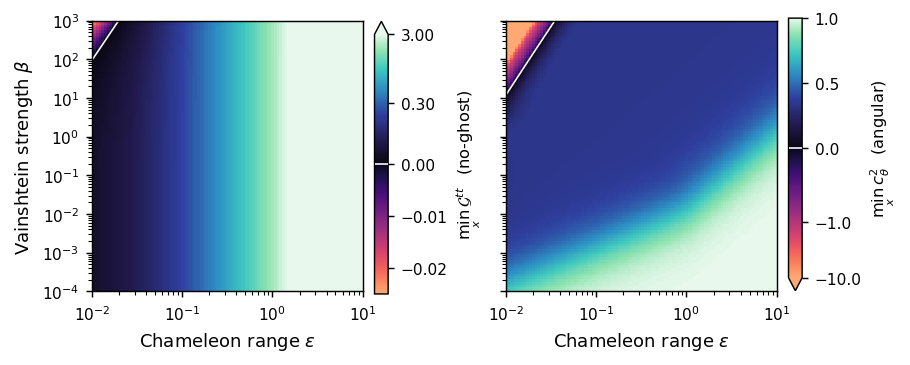

In [3]:
# warm (unstable) below zero, cool (stable) above, meeting at black
neg = cm.magma(np.linspace(0.82, 0.06, 128))
pos = styling.sequential()(np.linspace(0.0, 1.0, 128))
cmap = ListedColormap(np.vstack([neg, pos]), 'stability')
cmap.set_bad('0.82')                      # unsolved pixels

# G^tt: linear on the ghost side, logarithmic on the healthy side
GN, GX, Z0 = -0.025, 3.0, 0.05
_L = np.log1p(GX / Z0)
def _fwd(z):
    z = np.asarray(z, float)
    return np.where(z < 0, 0.5 * (1 + z / (-GN)),
                    0.5 + 0.5 * np.log1p(np.clip(z, 0, None) / Z0) / _L)
def _inv(u):
    u = np.asarray(u, float)
    return np.where(u < 0.5, (u / 0.5 - 1) * (-GN), Z0 * np.expm1((u - 0.5) / 0.5 * _L))

fig = plt.figure(figsize=(styling.WIDE, 3.4))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 0.32, 1], wspace=0.05)
axa, axb = fig.add_subplot(gs[0]), fig.add_subplot(gs[2])

def panel(ax, Z, norm):
    Zm = np.ma.masked_invalid(Z)
    im = ax.pcolormesh(epss, betas, Zm, cmap=cmap, shading='nearest', norm=norm)
    ax.contour(epss, betas, Zm, levels=[0.0], colors='w', linewidths=0.9)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_box_aspect(1)
    ax.set_xlim(epss[0], epss[-1]); ax.set_ylim(betas[0], betas[-1])
    ax.set_xlabel(r'Chameleon range $\epsilon$')
    return im

ima = panel(axa, Gmin, FuncNorm((_fwd, _inv), vmin=GN, vmax=GX))
# c_theta^2 diverges as G^tt -> 0, so its depth is a pole, not a scale: the
# negative half is logarithmic with a -10 floor (the same clip the sweep applies),
# which resolves the approach to zero without distorting the positive half.
CV, Z0C = -10.0, 0.05
_LN = np.log1p(-CV / Z0C)
def _cfwd(z):
    z = np.asarray(z, float)
    return np.where(z < 0, 0.5 - 0.5 * np.log1p(np.clip(-z, 0, None) / Z0C) / _LN,
                    0.5 + 0.5 * np.clip(z, 0, None))
def _cinv(u):
    u = np.asarray(u, float)
    return np.where(u < 0.5, -Z0C * np.expm1((0.5 - u) * 2 * _LN), (u - 0.5) * 2)
imb = panel(axb, Cmin, FuncNorm((_cfwd, _cinv), vmin=CV, vmax=1.0))
axa.set_ylabel(r'Vainshtein strength $\beta$'); axb.set_yticklabels([])

cba = fig.colorbar(ima, ax=axa, fraction=0.046, pad=0.04, extend='max')
cba.set_label(r'$\min_x\,\mathcal{G}^{tt}$  (no-ghost)', fontsize=9)
cba.set_ticks([-0.02, -0.01, 0.0, 0.30, 3.00])
cbb = fig.colorbar(imb, ax=axb, fraction=0.046, pad=0.04, extend='min')
cbb.set_label(r'$\min_x\,c_\theta^2$  (angular)', fontsize=9)
cbb.set_ticks([CV, -1.0, 0.0, 0.5, 1.0])
for cb in (cba, cbb):                     # mark zero, matching the map contour
    cb.ax.plot([0, 1], [float(cb.norm(0.0))] * 2, transform=cb.ax.transAxes,
               color='w', lw=0.9, zorder=5)

fig.savefig('stability.png', bbox_inches='tight', dpi=200)
plt.show()

## Is the unstable corner real?

The sweep runs at a loose tolerance, and $\mathcal{G}^{tt}$ depends on $\Box y$ — a second derivative, which amplifies solver error. Since the figure's content is the *sign* of each quantity, the pixels worth checking are those closest to zero: re-solve them at progressively tighter tolerance and confirm they stay on the same side.

In [4]:
flat = sorted((abs(Gmin[i, j]), i, j) for i in range(len(betas)) for j in range(len(epss))
              if np.isfinite(Gmin[i, j]))
print(f"{'eps':>9}{'beta':>11}{'tol=3e-3':>12}{'tol=3e-4':>12}   sign stable?")
for _, i, j in flat[:4]:
    eps, beta = float(epss[j]), float(betas[i])
    vals = [sweep.pixel(eps, beta, tol=t, max_nodes=6_000_000) for t in (3e-3, 3e-4)]
    vals = [v[0] if v else np.nan for v in vals]
    signs = {np.sign(v) for v in vals if np.isfinite(v)}
    fmt = lambda v: f'{v:>12.6f}' if np.isfinite(v) else f"{'failed':>12}"
    print(f'{eps:>9.4g}{beta:>11.4g}' + ''.join(fmt(v) for v in vals)
          + f"   {'yes' if len(signs) <= 1 else 'NO'}")

      eps       beta    tol=3e-3    tol=3e-4   sign stable?


  0.01072      120.5   -0.000028   -0.000028   yes


  0.01233      196.3   -0.000109   -0.000095   yes


  0.01417      319.9   -0.000179   -0.000163   yes


   0.0163      521.4   -0.000256   -0.000238   yes
